<a href="https://colab.research.google.com/github/flaviofrancisco/ai-masters-projects/blob/main/01-generative-ai/gen_ai_fundamentals_project_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Combined and resolved package installations
# Installs unsloth, uv, vllm-bnb-plugin, and compatible PyTorch/Torchvision to align with vLLM requirements
!pip install torch==2.14.0 torchvision==0.29.0 setuptools==80.10.2
!pip install "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install uv vllm-bnb-plugin

  Using cached torch-2.14.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (37 kB)
  Using cached torchvision-0.29.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (5.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 52.7 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 187.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 51.6 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 177.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 167.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 64.1 MB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 207.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 184.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 117.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 81.2 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 72.5

  Cloning https://github.com/unslothai/unsloth.git to /tmp/pip-install-flkaldv4/unsloth_781127e96eb1459a840586b473632e6c
  Running command git clone --filter=blob:none --quiet https://github.com/unslothai/unsloth.git /tmp/pip-install-flkaldv4/unsloth_781127e96eb1459a840586b473632e6c
ERROR: Operation cancelled by user
^C


## Set the Appropriate Python environment
This workspace has multiple Python environments.
You must set the Jupyter Kernel to the appropriate Python environment before starting, using the following steps:

* Click on the **Select Kernel** button.
* Use **Jupyter Kernel** as the Python source.
* Select Python **(venv2)**

# Project: Teaching an LLM to Reason

In this project, you will teach an LLM to use step-by-step reasoning to answer the question: "How many X's are there in the word Y?"

Counting letters in a word is a surprisingly complex task for an LLM. Just as human beings would not be able to answer such a question for longer words without breaking down the word into its individual letters and then counting them, LLMs cannot be similarly expected to be able to respond without using smaller reasoning steps.

For example, to count the number of o's in the word room, one could use the following reasoning:

```
Question: How many of the letter "o" are there in the word "room"
Answer: 2
Response:

<reasoning>
Letter-by-letter spelling:
1. r - 0 o's so far
2. o - 1 o's so far
3. o - 2 o's so far
4. m - 2 o's so far

The letter "o" appears 2 times in the word "room".
</reasoning>
<answer>
2
</answer>
```

In this project we will use the reinforcement learning method GRPO (Group Relative Policy Optimization, of DeepSeek fame) to take a large language model that has been fine-tuned for following instructions and teach it how to break a word down into its letters and then count the requested letter.

We will complete the following steps:

* Set up the notebook
* Create a letter-counting dataset
* Create the reward functions
* Train the model
* View the results

NOTE: This notebook will have you focus on several important aspects of training a GRPO model using LoRA:

1. Configuring LoRA adapters for parameter-efficient fine tuning
2. Selecting reward functions that help the model efficiently find its way to the correct answer (also called reward shaping)
3. Finding hyperparameters that help the model increase the rewards earned more quickly and reliably
4. Learning how to start with smaller experiments and to work your way up to longer experiments.

## Set up the notebook

We'll install dependencies needed for the project, namely `unsloth` and `vllm`, which are useful for fine-tuning LLMs with even just 15GB of VRAM.

In [1]:
# 1. Install uv tool
!pip install uv

# 2. Download requirements.txt from your GitHub repository
# TODO: Replace the URL below with the raw URL to your GitHub repository's requirements.txt
GITHUB_REQUIREMENTS_URL = "https://raw.githubusercontent.com/flaviofrancisco/ai-masters-projects/main/01-generative-ai/requirements.txt"
!curl -sSL {GITHUB_REQUIREMENTS_URL} -o requirements.txt

# 3. Install packages from requirements.txt using uv
!uv pip install --system -r requirements.txt

Using Python 3.13.16 environment at: /usr
Resolved 231 packages in 498ms
Prepared 3 packages in 32ms
Uninstalled 11 packages in 375ms
Installed 11 packages in 196ms
 - compressed-tensors==0.15.0.1
 + compressed-tensors==0.17.0
 - cuda-python==13.0.3
 + cuda-python==13.5.0
 - flashinfer-python==0.6.6
 + flashinfer-python==0.7.2.post1
 - fsspec==2026.9.0
 + fsspec==2026.2.0
 - llguidance==1.3.0
 + llguidance==1.7.6
 - llvmlite==0.44.0
 + llvmlite==0.47.0
 - numba==0.61.2
 + numba==0.65.0
 - nvidia-cudnn-frontend==1.18.0
 + nvidia-cudnn-frontend==1.32.2
 - outlines-core==0.2.11
 + outlines-core==0.2.14
 - torchaudio==2.10.0
 + torchaudio==2.11.0
 - vllm==0.19.1
 + vllm==0.33.0


In [2]:
# Force re-install both torchvision and Pillow together to align their C-extensions
!pip install --upgrade --force-reinstall --no-cache-dir Pillow torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 433.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 530.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.2/539.2 MB 361.3 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB 451.0 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 478.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 453.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 MB 467.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 464.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.9/404.9 MB 494.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 476.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 MB 462.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 537.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 MB 492.9 MB/s  0

⚠️ **CRITICAL STEP**:
After running the cell above, you **must** click **"Restart"** (the circular arrow icon in the top toolbar) to reload the correct Pillow C-extensions into the runtime.

Once restarted, verify that your kernel is still set to **Python (venv2)** in the top right, and then run cell `r2iACfV76LPk` again.

In [1]:
# Load ipython-autotime to see how long each cell take to run
# No changes needed in this cell

!pip install -q ipython-autotime
%load_ext autotime

time: 237 µs (started: 2026-11-05 21:51:39 +00:00)


In [2]:
# Verify we have enough GPU memory to run this project (at least 15360MiB)
# No changes needed in this cell

!nvidia-smi

Thu Nov  5 21:51:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   54C    P8             13W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Troubleshooting Common Errors

---

### `RuntimeError: Duplicate layer name`

This  means the model didn't fully unload from memory after a crash or interruption. A quick kernel restart clears it right up.

**Fix:**
1. Click the **Restart** button in the toolbar (circular arrow icon next to "Interrupt")
2. Wait for the kernel to come back up
3. Check the top-right corner still shows **Python (venv2)**
4. Run all cells again from the top

> Click **Restart**, not **End Lab** — ending the lab closes your whole GPU session.

---

### `NotImplementedError: Unsloth cannot find any torch accelerator`

The GPU is fine. The notebook is just running in the wrong Python environment. It needs **Python (venv2)** to access the GPU.

**Fix:**
1. Click **"Select Kernel"** in the top-right corner
2. Choose **Jupyter Kernel** from the dropdown
3. Select **Python (venv2)**
4. Re-run the failing cell

**Don't see Python (venv2)?**
Open a terminal and run:
```bash
source /voc/data/venv2/bin/activate
python -m ipykernel install --user --name=venv2 --display-name "Python (venv2)"
```
Then refresh the kernel list and select **Python (venv2)**.

## Try Prompt Engineering to Count Letters

Let's work on the system prompt a little to see if we can get the model to count the number of the letter `g` in `engage`.


Here you must:
* Write clear instructions
* Break the problem down into steps (Chain-of-Thought prompting)
* Provide at least one example for the model to follow (Few-shot prompting)

In [1]:
# Load the `Qwen 2.5 3B Instruct`, and set parameters for the project
# The first time unsloth is imported, it will do its magic and patch the modules
# it works with. This may take 2-5 minutes.
# TODO: Fill in the missing parts marked with **********

import unsloth

from unsloth import FastLanguageModel
import torch

max_seq_length = 384  # Increase if you get errors about the sequence length

# Set the LoRA rank to an appropriate value
# Read about setting LoRA rank:
# https://docs.unsloth.ai/get-started/fine-tuning-llms-guide/lora-hyperparameters-guide

# A higher rank increases model capacity, but also memory usage.
lora_rank = 16  # Explain your choice

# Load the Instruct model in 4-bit mode
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="Qwen/Qwen2.5-3B-Instruct",
    max_seq_length=max_seq_length,
    load_in_4bit=True,  # We'll use quantization!
    fast_inference=True,  # This uses vllm for faster inference
    max_lora_rank=lora_rank,
    gpu_memory_utilization=0.5,  # You can reduce this if you get an memory error
)

model = FastLanguageModel.get_peft_model(
    model,
    r=lora_rank,
    target_modules=[
        # Read about choosing adapters for LoRA:
        # https://docs.unsloth.ai/get-started/fine-tuning-llms-guide/lora-hyperparameters-guide
        # Choose the target modules/adapters for your LoRA model
        # Explanation: to target both MLP and attention layers to increase accuracy.
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
    lora_alpha=lora_rank * 2,
    use_gradient_checkpointing="unsloth",  # Unsloth enables longer contexts
    # See: https://github.com/unslothai/unsloth
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/usr/local/lib/python3.13/dist-packages/unsloth/_gpu_init.py:490: UserWarning: Unsloth: torchcodec is installed but cannot load its native libraries although FFmpeg is on the loader path; likely an FFmpeg major it does not support (it takes 4 to 8), a missing CUDA NPP runtime (nvidia-npp), or a build that does not match this torch; audio datasets decode through soundfile and PyAV instead (wav/flac/mp3/ogg, m4a/aac/webm). torchcodec 0.17.0 is incompatible with torch 2.10.0+cu128; install a matching build with `pip install --index-url https://download.pytorch.org/whl/cu128 'torchcodec>=0.10,<0.11.0'`.
  disable_torchcodec_if_broken()


🦥 Unsloth Zoo will now patch everything to make training faster!
INFO 11-05 21:53:32 [vllm_utils.py:1141] Unsloth: Patching vLLM v1 graph capture
==((====))==  Unsloth 2026.11.2: Fast Qwen2 patching. Transformers: 5.17.0. vLLM: 0.19.1.
   \\   /|    NVIDIA L4. Num GPUs = 1. Max memory: 22.034 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 8.9. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not planning a device map; vLLM places its own weights. Using `sequential`.
Unsloth: Patched vLLM's piecewise graph-partition pass so compilation_config=3 (CUDA graphs) works with LoRA.
Unsloth: Not an error, but `level` is not supported in vLLM.config.CompilationConfig. Skipping.
Unsloth: Not an error, but `use_cudagraph` is not supported in vLLM.config.CompilationConfig. Skipp

<frozen importlib._bootstrap_external>:1329: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
<frozen importlib._bootstrap_external>:1329: FutureWarning: The cuda.nvrtc module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.nvrtc module instead.


INFO 11-05 21:53:37 [scheduler.py:238] Chunked prefill is enabled with max_num_batched_tokens=4096.
Unsloth: vLLM Bitsandbytes config using kwargs = {'load_in_8bit': False, 'load_in_4bit': True, 'bnb_4bit_compute_dtype': 'bfloat16', 'bnb_4bit_quant_storage': 'uint8', 'bnb_4bit_quant_type': 'nf4', 'bnb_4bit_use_double_quant': True, 'llm_int8_enable_fp32_cpu_offload': False, 'llm_int8_has_fp16_weight': False, 'llm_int8_skip_modules': ['lm_head', 'multi_modal_projector', 'merger', 'modality_projection', 'model.layers.2.mlp', 'model.layers.3.mlp', 'model.layers.30.mlp'], 'llm_int8_threshold': 6.0}
INFO 11-05 21:53:37 [vllm.py:790] Asynchronous scheduling is enabled.
INFO 11-05 21:53:38 [core.py:105] Initializing a V1 LLM engine (v0.19.1) with config: model='/root/.cache/huggingface/hub/models--unsloth--Qwen2.5-3B-Instruct-unsloth-bnb-4bit/snapshots/21d7790b1332196a5cf65ba72f2b46b659f74ddf', speculative_config=None, tokenizer='/root/.cache/huggingface/hub/models--unsloth--Qwen2.5-3B-Instruc

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


... (11 outputs left out)

Unsloth: Just some info: will skip parsing ['operator_norm', 'pre_feedforward_layernorm_2', 'k_norm', 'attention_norm', 'post_per_layer_input_norm', 'post_feedforward_layernorm_2', 'input_layernorm', 'k_layernorm', 'layer_norm2', 'post_feedforward_layernorm', 'post_layernorm', 'norm2', 'layer_norm1', 'post_feedforward_layernorm_1', 'q_norm', 'norm', 'q_layernorm', 'norm1', 'post_attention_layernorm', 'ffn_norm', 'pre_feedforward_layernorm']


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Performing substitution for additional_keys=set()
Unsloth: Just some info: will skip parsing ['operator_norm', 'pre_feedforward_layernorm_2', 'k_norm', 'attention_norm', 'post_per_layer_input_norm', 'post_feedforward_layernorm_2', 'input_layernorm', 'k_layernorm', 'layer_norm2', 'post_feedforward_layernorm', 'post_layernorm', 'norm2', 'layer_norm1', 'post_feedforward_layernorm_1', 'cross_attn_input_layernorm', 'q_norm', 'norm', 'q_layernorm', 'norm1', 'cross_attn_post_attention_layernorm', 'post_attention_layernorm', 'ffn_norm', 'pre_feedforward_layernorm']


Unsloth 2026.11.2 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


In [2]:
# First, let's see what happens when we have a blank system prompt
# No changes needed in this cell
SYSTEM_PROMPT = """"""
USER_PROMPT = 'How many of the letter "g" are there in the word "engage"'

# Convert the chat messages to a single string so the model can complete it
text_for_completion = tokenizer.apply_chat_template(
    conversation=[
        {"role": "system", "content": SYSTEM_PROMPT},
        {
            "role": "user",
            "content": USER_PROMPT,
        },
    ],
    tokenize=False,
    add_generation_prompt=True,
)

from vllm import SamplingParams

# Set the LLM sampling parameters
sampling_params = SamplingParams(
    temperature=0.8,
    top_p=0.95,
    max_tokens=2048,
)

# Generate the text completion
output = (
    model.fast_generate(
        [text_for_completion],
        sampling_params=sampling_params,
        lora_request=None,
    )[0]
    .outputs[0]
    .text
)

# Print the text input for the model and the model's output
print("=== TEXT FOR COMPLETION ===")
print(text_for_completion)
print("=== GENERATED OUTPUT ===")
print(output)

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

=== TEXT FOR COMPLETION ===
<|im_start|>system
<|im_end|>
<|im_start|>user
How many of the letter "g" are there in the word "engage"<|im_end|>
<|im_start|>assistant

=== GENERATED OUTPUT ===
To determine how many times the letter "g" appears in the word "engage," we can simply go through each letter of the word:

1. e
2. n
3. g
4. a
5. n
6. g
7. e

From this breakdown, we can see that the letter "g" appears twice in the word "engage."


Without any prompting the model will generate an output such as this:

```
=== GENERATED OUTPUT ===
There is one letter "g" in the word "engage".
```

Now let's work on the system prompt to help the model break this problem down into steps, which might help it get the right answer (2 `g`'s in `engage`)

In [3]:
# Let's work on a new system prompt that will help the model break this problem
# down into steps, for example, using "letter-by-letter" spelling.
# DONE: Fill in the missing parts marked with **********

# Use a CoT prompt with at least one example
SYSTEM_PROMPT = """
  Question: How many of the letter "o" are there in the word "room"
  Answer: 2
  Response:

  <reasoning>
  Letter-by-letter spelling:
  1. r - 0 o's so far
  2. o - 1 o's so far
  3. o - 2 o's so far
  4. m - 2 o's so far

  The letter "o" appears 2 times in the word "room".
  </reasoning>
  <answer>
  2
  </answer>
"""


USER_PROMPT = 'How many of the letter "g" are there in the word "engage"'

# Convert the chat messages to a single string so the model can complete it
text_for_completion = tokenizer.apply_chat_template(
    conversation=[
        {"role": "system", "content": SYSTEM_PROMPT},
        {
            "role": "user",
            "content": USER_PROMPT,
        },
    ],
    tokenize=False,
    add_generation_prompt=True,
)

from vllm import SamplingParams

# Set the LLM sampling parameters
sampling_params = SamplingParams(
    temperature=0.8,
    top_p=0.95,
    max_tokens=2048,
)

# Generate the text completion
output = (
    model.fast_generate(
        [text_for_completion],
        sampling_params=sampling_params,
        lora_request=None,
    )[0]
    .outputs[0]
    .text
)

# Print the text input for the model and the model's output
print("=== TEXT FOR COMPLETION ===")
print(text_for_completion)
print("=== GENERATED OUTPUT ===")
print(output)

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

=== TEXT FOR COMPLETION ===
<|im_start|>system

  Question: How many of the letter "o" are there in the word "room"
  Answer: 2
  Response:

  <reasoning>
  Letter-by-letter spelling:
  1. r - 0 o's so far
  2. o - 1 o's so far
  3. o - 2 o's so far
  4. m - 2 o's so far

  The letter "o" appears 2 times in the word "room".
  </reasoning>
  <answer>
  2
  </answer>
<|im_end|>
<|im_start|>user
How many of the letter "g" are there in the word "engage"<|im_end|>
<|im_start|>assistant

=== GENERATED OUTPUT ===
Let's analyze the word "engage" letter by letter:

1. e - 0 g's
2. n - 0 g's
3. g - 1 g
4. a - 0 g's
5. n - 0 g's
6. e - 0 g's
7. a - 0 g's

As we can see, the letter "g" appears only once in the word "engage".

Therefore, the answer is 1.


Did your new prompt get the right answer? Did the model follow all of your instructions?

Maybe yes, maybe no. Either way, we'll want the model to reliably complete this challenge. So let's use GRPO to help it!

## Create a letter-counting dataset

To train a model, we'll first need to create a dataset. We'll use the HuggingFace `datasets` package.

In [4]:
# Create a list of words of different lengths
# No changes are needed in this cell.

ALL_WORDS = [
    "idea",
    "glow",
    "rust",
    "maze",
    "echo",
    "wisp",
    "veto",
    "lush",
    "gaze",
    "knit",
    "fume",
    "plow",
    "void",
    "oath",
    "grim",
    "crisp",
    "lunar",
    "fable",
    "quest",
    "verge",
    "brawn",
    "elude",
    "aisle",
    "ember",
    "crave",
    "ivory",
    "mirth",
    "knack",
    "wryly",
    "onset",
    "mosaic",
    "velvet",
    "sphinx",
    "radius",
    "summit",
    "banner",
    "cipher",
    "glisten",
    "mantle",
    "scarab",
    "expose",
    "fathom",
    "tavern",
    "fusion",
    "relish",
    "lantern",
    "enchant",
    "torrent",
    "capture",
    "orchard",
    "eclipse",
    "frescos",
    "triumph",
    "absolve",
    "gossipy",
    "prelude",
    "whistle",
    "resolve",
    "zealous",
    "mirage",
    "aperture",
    "sapphire",
]

print(len(ALL_WORDS))

ALL_WORDS[:10]

62


['idea',
 'glow',
 'rust',
 'maze',
 'echo',
 'wisp',
 'veto',
 'lush',
 'gaze',
 'knit']

In [5]:
# Create the dataset as a Hugging Face Dataset using Dataset.from_generator
# No changes needed in this cell

from datasets import Dataset
import random


# Go through the letters from the words (as well as letters not in the words),
# and create a labelled dataset with all the different combinations.
# For example for the word gaze:
# 1. How many i's are in idea? <-- count should be 1
# 2. How many d's are in idea? <-- count should be 1
# 3. How many e's are in idea? <-- count should be 1
# 4. How many a's are in idea? <-- count should be 1
# 5. How many b's are in idea? <-- a letter not in word (count should be zero)
def generate_records():
    for word in ALL_WORDS:
        for letter in sorted(set(word)):
            yield {"words": word, "letters": letter, "counts": word.count(letter)}

        # pick random letters not in the word
        num_letters_not_in_word_left = int(len(word) // 7 + 1)

        random.seed(hash(word))

        all_letters = list("abcdefghijklmnopqrstuvwxyz")

        random.shuffle(all_letters)
        for letter in all_letters:
            if letter not in word:
                yield {"words": word, "letters": letter, "counts": 0}
                num_letters_not_in_word_left -= 1
            if num_letters_not_in_word_left == 0:
                break


ds = Dataset.from_generator(generate_records)

# Show the first item
ds[0]

{'words': 'idea', 'letters': 'a', 'counts': 1}

In [6]:
# Add the entire prompt (system + user) and the answer to the dataset
# We'll use a prompt that spells out the word letter-by-letter
# No changes needed in this cell

import re
from datasets import load_dataset, Dataset

# Simple CoT prompt (zero-shot)
SYSTEM_PROMPT = """
Respond in the following format:
<reasoning>
Counting the number of [letter_to_count]'s in the word [word]
1. [first letter] - [count of requested letter so far] so far
2. [second letter] - [count of requested letter so far] so far
...
</reasoning>
<answer>
[number]
</answer>
"""

ds = ds.map(
    lambda x: {  # type: ignore
        "prompt": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {
                "role": "user",
                "content": 'How many of the letter "{}" are there in the word "{}"'.format(
                    x["letters"], x["words"]
                ),
            },
        ],
    }
)

ds[0]

{'words': 'idea',
 'letters': 'a',
 'counts': 1,
 'prompt': [{'content': "\nRespond in the following format:\n<reasoning>\nCounting the number of [letter_to_count]'s in the word [word]\n1. [first letter] - [count of requested letter so far] so far\n2. [second letter] - [count of requested letter so far] so far\n...\n</reasoning>\n<answer>\n[number]\n</answer>\n",
   'role': 'system'},
  {'content': 'How many of the letter "a" are there in the word "idea"',
   'role': 'user'}]}

In [7]:
# Let's see how well the model runs out-of-the-box
# No changes needed in this cell

text = tokenizer.apply_chat_template(
    ds[0]["prompt"], tokenize=False, add_generation_prompt=True
)

from vllm import SamplingParams

sampling_params = SamplingParams(
    temperature=0.8,
    top_p=0.95,
    max_tokens=1024,
)
output = (
    model.fast_generate(
        [text],
        sampling_params=sampling_params,
        lora_request=None,
    )[0]
    .outputs[0]
    .text
)

print(output)

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

<reasoning>
Counting the number of a's in the word idea
1. i - 0 so far
2. d - 1 so far
3. e - 2 so far
4. a - 3 so far
</reasoning>
<answer>
3
</answer>


## Create Reward Functions

One goal of creating reward functions is to guide the model toward behaviors that help it reach its goal (counting the occurrences of a letter within a word) more easily. Since there is more than one way to carry out any step-by-step task (e.g. whether or not you use bullet points to separate your steps), there's a bit of judgement involved in choosing what behaviors to reward, i.e. how do we provide partial credit or "shape" our rewards?

In this case we will encourage the model to (whether or not this structure is best):
* use numbers for bullet points when spelling out the word
* to spell the word correctly
* to count the requested letter correctly
* to use the requested reasoning format
* to get the final answer correct.


### Numbering reward function

In [8]:
# Let's work on a function that the numbering in the bullet points is correct
# When using GRPO, we lean on reward functions that are relatively easy to
# compute, thus removing the need to have a second large model just for
# evaluation.
# In this case, we'll use regular expressions quite a bit.
# TODO: Fill in the missing parts marked with **********


def extract_letter_numbering(response):
    """Extract the numbers at the beginning of the line

    Example:
    1. g - 1 so far
    2. o - 1 so far
    3. a - 2 so far
    4. a - 2 so far
    5. l - 2 so far
    returns [1, 2, 3, 4, 5]
    """
    import re

    # We use a regular expression to find lines of the form:
    # '\n[number]. [letter]'
    pattern = r"\n(\d+). [a-z]"

    # Use `re` to find all matches of the pattern in the response
    matches = re.findall(pattern, response, flags=re.IGNORECASE)
    if matches:
        return [int(m) for m in matches]
    return []


assert extract_letter_numbering(
    """
1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
4. a - 2 so far
5. l - 2 so far
"""
) == [1, 2, 3, 4, 5]


def numbering_reward_func(completions, words, **kwargs) -> list[float]:
    """Provides a reward for getting the numbering at the beginning of the line correct

    1. g - 1 so far <-- Good in-order numbering
    2. o - 1 so far <-- Good in-order numbering
    3. a - 2 so far <-- Good in-order numbering
    3. l - 2 so far <-- Bad numbering, out-of-order, 3 should be 4
    1. l - 2 so far <-- Bad numbering, extra letter and out-of-order
    1. l - 2 so far <-- Bad numbering, extra letter and out-of-order

    """
    responses = [completion[0]["content"] for completion in completions]

    res = []
    for response, word in zip(responses, words):
        reward = 0

        for ix, spell_number in enumerate(extract_letter_numbering(response)):
            line_number = ix + 1

            # Get points for in-order numbering
            if spell_number == line_number:
                # Done: Provide a reward for in-order numbering
                # (positive for good behavior, negative for bad)
                reward += 1
            # Otherwise lose points
            else:
                # Done: Provide a reward for out-of-order numbering
                # (positive for good behavior, negative for bad)
                reward -= 1

            # Lose extra points for continuing beyond the length of the word
            if line_number > len(word):  # We use the index of the line
                # Done: Provide a reward for continuing beyond the length of the word
                # (positive for good behavior, negative for bad)
                reward -= 1

        res.append(reward / len(word))
    return res


res = numbering_reward_func(
    completions=[
        [
            {  # Worse response
                "content": """<reasoning>
Here is a letter by letter spelling:
1. g - 1 so far <-- Good in-order numbering
2. o - 1 so far <-- Good in-order numbering
3. a - 2 so far <-- Good in-order numbering
3. l - 2 so far <-- Bad numbering, out-of-order, 3 should be 4
1. l - 2 so far <-- Bad numbering, extra letter and out-of-order
1. l - 2 so far <-- Bad numbering, extra letter and out-of-order
</reasoning>
<answer>2</answer>"""
            },
        ],
        [
            {  # Better response
                "content": """<reasoning>
Here is a letter by letter spelling:
1. g - 1 so far <-- Good in-order numbering
2. o - 1 so far <-- Good in-order numbering
3. a - 2 so far <-- Good in-order numbering
3. l - 2 so far <-- Bad numbering, out-of-order, 3 should be 4
</reasoning>
<answer>2</answer>"""
            },
        ],
    ],
    words=["goal", "goal"],
)
print(res)

assert res[1] > res[0], "The better response should have a higher reward"

[-0.5, 0.5]


### Spelling reward function

In [9]:
# Reward correct spelling of the word
# Done: Fill in the missing parts marked with **********


def extract_spelling(response):
    """Extract the spelling from the response

    Example:
    1. g - 1 so far
    2. o - 1 so far
    3. a - 2 so far
    3. l - 2 so far
    5. l - 2 so far
    Returns "goall"
    """
    import re

    pattern = r"\n\d+. ([a-z])"
    matches = re.findall(pattern, response, flags=re.IGNORECASE)
    if matches:
        return "".join([m for m in matches])
    return ""


extract_spelling(
    """Here is a letter by letter spelling:

1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
3. l - 2 so far
5. l - 2 so far
"""
) == "goall"


from difflib import SequenceMatcher

def spelling_reward_func(completions, words, **kwargs) -> list[float]:
    res = []
    for completion, word in zip(completions, words):
        spelled = extract_spelling(completion[0]["content"]).lower()
        if spelled == word:
            res.append(1.0)
        else:
            res.append(SequenceMatcher(None, spelled, word).ratio() - 0.5)  # in [-0.5, 0.5)
    return res


res = spelling_reward_func(
    completions=[
        [  # Worse response
            {
                "content": """<reasoning>
Here is a letter by letter spelling:
1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
4. l - 2 so far
5. l - 2 so far
</reasoning>
<answer>2</answer>"""
            }
        ],
        [  # Better Response
            {
                "content": """<reasoning>
Here is a letter by letter spelling:
1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
4. l - 2 so far
</reasoning>
<answer>2</answer>"""
            }
        ],
    ],
    words=["goal", "goal"],
)

print(res)

assert res[1] > res[0], "The better response should have a higher reward"

[0.38888888888888884, 1.0]


### Counting reward function

In [10]:
# Let's reward the model for properly counting the occurrences of a letter in a word
# Done: Fill in the missing parts marked with **********


def get_resp_letters_and_counts(response):
    """Extract the letters and counts from the response

    Example:
    1. g - 1 so far
    2. o - 1 so far
    3. a - 2 so far
    4. a - 2 so far
    5. l - 2 so far
    returns [('g', 1), ('o', 1), ('a', 2), ('a', 2), ('l', 2)]
    """
    import re

    pattern = r"\n(\d+)\. ([a-z])\D*(\d+)"

    # Find strings matching e.g. "2. a - 2 so far"
    matches = re.findall(pattern, response, flags=re.IGNORECASE)

    if not matches:
        return []

    return [
        (matched_letter, matched_count_so_far)
        for _, matched_letter, matched_count_so_far in matches
    ]


assert get_resp_letters_and_counts(
    """
1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
4. a - 2 so far
5. l - 2 so far
"""
) == [("g", "1"), ("o", "1"), ("a", "2"), ("a", "2"), ("l", "2")]


def counting_reward_func(completions, letters, words, **kwargs) -> list[float]:
    res = []
    for completion, letter, word in zip(completions, letters, words):
        pairs = get_resp_letters_and_counts(completion[0]["content"])
        if not pairs:
            res.append(-1.0)
            continue
        expected = [word[: i + 1].count(letter) for i in range(len(word))]
        score = 0
        for i, (_, count) in enumerate(pairs):
            if i < len(expected) and count == str(expected[i]):
                score += 1
            else:
                score -= 1
        res.append(score / len(word))
    return res


res = counting_reward_func(
    completions=[
        [  # Worse response
            {
                "content": """<reasoning>\nHere is a letter by letter spelling:

1. g - 0 so far
2. o - 0 so far
3. a - 1 so far
4. a - 2 so far
5. l - 0 so far

\n</reasoning>\n<answer>\nThis is my answer.\n</answer>"""
            }
        ],
        [  # Better response
            {
                "content": """<reasoning>\nHere is a letter by letter spelling:

1. g - 1 so far
2. o - 1 so far
3. a - 1 so far
4. a - 1 so far
5. l - 1 so far

\n</reasoning>\n<answer>\nThis is my answer.\n</answer>"""
            }
        ],
    ],
    letters=["g", "g"],
    words=["goal", "goal"],
)

print(res)

assert res[1] > res[0], "The better response should have a higher reward"


[-0.75, 0.75]


### Formatting reward functions



In [11]:
# Reward the model for providing the response in a specific format
# Done: Fill in the missing parts marked with **********


def extract_xml_answer(text: str) -> str:
    """Extracts the string between <answer> and </answer> tags."""
    import re

    pattern = r"<answer>(.*?)</answer>"
    match = re.search(pattern, text, re.DOTALL)
    if match:
        return match.group(1).strip()
    return ""


assert (
    extract_xml_answer("""
<reasoning>
This is my reasoning.
</reasoning>
<answer>SUPERCALIFRAGILISTICEXPIALIDOCIOUS</answer>
""")
    == "SUPERCALIFRAGILISTICEXPIALIDOCIOUS"
)


def format_reward_func(completions, **kwargs) -> list[float]:
    """Reward function that checks if the completion has a specific format."""
    pattern = r"\s*<reasoning>.*?</reasoning>\s*<answer>.*?</answer>"

    res = []

    for completion in completions:
        reward = 0.0

        # Extract the response content
        response = completion[0]["content"]

        # Check if the response matches the pattern
        match = re.match(pattern, response, flags=re.MULTILINE | re.DOTALL)

        # If it matches, return 0.5, otherwise return 0.0
        if match:
            reward = 0.5
        # Extract the answer from the response
        else:
          reward = -0.5

        # If the answer is an integer, add 0.5 to the reward
        if extract_xml_answer(response).isdigit():
            reward += 0.5

        res.append(reward)
    return res


res = format_reward_func(
    completions=[
        [{"content": "This is my answer"}],
        [
            {
                "content": "<reasoning>\nThis is my reasoning.\n</reasoning>\n<answer>\n3\n</answer>"
            }
        ],
    ]
)

print(res)

assert res[1] > res[0], "The better response should have a higher reward"

[-0.5, 1.0]


### Task correctness reward function

In [12]:
# Reward the model for providing the correct answer
# Done: Fill in the missing parts marked with **********


def correct_answer_reward_func(prompts, completions, counts, **kwargs) -> list[float]:
    res = []
    for completion, answer in zip(completions, counts):
        text = completion[0]["content"]
        extracted = extract_xml_answer(text)
        pairs = get_resp_letters_and_counts(text)
        last_count = pairs[-1][1] if pairs else None
        if extracted == str(answer) and last_count == extracted:
            res.append(2.0)   # correct and supported by the reasoning
        elif extracted == str(answer):
            res.append(0.5)   # correct but the reasoning doesn't back it up
        else:
            res.append(0.0)
    return res


res = correct_answer_reward_func(
    prompts=[
        [{"content": """How many..."""}],
        [{"content": """How many..."""}],
    ],
    completions=[
        [{"content": """<reasoning>.../reasoning>\n<answer>\n3\n</answer>"""}],
        [{"content": """<reasoning>.../reasoning>\n<answer>\n3\n</answer>"""}],
    ],
    letters=["g", "g"],
    counts=[0, 3],
)

print(res)

assert res[1] > res[0], "The better response should have a higher reward"


--------------------
Question: How many...
Answer: 0
Response: <reasoning>.../reasoning>
<answer>
3
</answer>
Extracted: 3
Correct: False!
    
[0.0, 2.0]


### List the reward functions

In [13]:
# List out the reward functions we will use
# No changes needed in this cell

REWARD_FUNCS = [
    numbering_reward_func,
    spelling_reward_func,
    counting_reward_func,
    format_reward_func,
    correct_answer_reward_func,
]

## Train the model

Now set up GRPO Trainer and configurations!

As you run the trainer, the goal is to see the various `reward` columns increase.

GRPO training is noisy: with the small batches that fit on a T4, rewards jump around from step to step, and in an 80–100-step run the upward trend can be weak. Judge the overall direction — a rolling mean helps: `log_df["rewards/correct_answer_reward_func/mean"].rolling(10).mean().plot()`. If your trend is flat or unstable, you can still pass: show the plot or log, explain what you think happened, change one setting, and report the result of a short re-run (about 20–30 steps is enough).

After 50 steps or more, you may notice some of the reward standard deviations begin to decrease, meaning that the different predictions are starting to converge on solutions that give similar rewards. If your model has learned the task, then you'll see the `correct_answer_reward_function` increase to its highest value (check the function to see what that is).

Here is an example, which successfully converged on a higher reward. Note, the values you see here will probably be different from yours, especially if your reward amounts are different.

| Step | Training Loss | reward   | reward_std | ... | kl      | rewards / correct_answer_reward_function / mean | rewards / correct_answer_reward_function / std |
|------|---------------|----------|------------|-----|---------|------------------------------------------|-----------------------------------------|
| 1    | 0.000000      | 7.961805 | 2.368493   | ... | 0.020369| 0.875000                                 | 1.024695                                |
| 2    | 0.000000      | 7.937500 | 1.352467   | ... | 0.016483| 0.875000                                 | 1.024695                                |
| 3    | 0.000000      | 1.894792 | 6.462189   | ... | 0.013677| 0.375000                                 | 0.806226                                |
| ...  | ...           | ...      | ...        | ... | ...     | ...                                      | ...                                     |
| 398  | 0.000100      | 13.000000| 0.000000   | ... | 0.088529| 2.000000                                 | 0.000000                                |
| 399  | 0.000100      | 13.000000| 0.000000   | ... | 0.088617| 2.000000                                 | 0.000000                                |
| 400  | 0.000100      | 13.000000| 0.000000   | ... | 0.096202| 2.000000                                 | 0.000000                                |


In [14]:
# Fill in the GRPO Parameters we'll use throughout this project
# Done: Fill in the missing parts marked with **********

# Read about the GRPO params here https://huggingface.co/docs/trl/main/en/grpo_trainer
COMMON_GRPO_TRAINING_PARAMS = dict(
    # Set appropriate values for `learning_rate` and `beta`
    learning_rate=2e-4,
    beta=0.001,
    # Set the batch size appropriately for your hardware.
    per_device_train_batch_size=4,
    num_generations=6,
    gradient_accumulation_steps=2,
    adam_beta1=0.9,
    adam_beta2=0.99,
    weight_decay=0.1,
    warmup_ratio=0.1,
    lr_scheduler_type="cosine",
    optim="adamw_8bit",
    logging_steps=1,
    max_prompt_length=256,
    max_completion_length=256,
    num_train_epochs=1,  # Set to 1 for a full training run
    save_steps=20,  # Save a checkpoint every 20 steps so a dropped session can resume
    save_total_limit=2,  # Keep only the two most recent checkpoints (each can be ~1 GB)
    max_grad_norm=0.1,
    report_to="none",  # Setting this value lets us use Weights and Biases
    output_dir="outputs",
    use_vllm=True,  # vLLM speeds up inference! See https://github.com/vllm-project/vllm
)

### Quick train

Let's train the model for just 5 steps (`max_steps=5`). As it runs we can double check we've set up our prompts correctly before running for a longer amount of time.

In [15]:
# Train for just a few steps for a few minutes
# This will allow us to observe the results and make any changes to our reward functions
# before starting a longer run. Note, you won't see much change in the average.
# reward values
# No changes are needed here

from trl import GRPOConfig, GRPOTrainer

# Short train to check on reward functions
training_args = GRPOConfig(
    **COMMON_GRPO_TRAINING_PARAMS,
    # We'll just run for a modest 5 steps to make sure everything works and to
    # estimate the amount of time it will take to run the full training.
    max_steps=5,
)
trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=REWARD_FUNCS,
    args=training_args,
    train_dataset=ds,
)
trainer_res = trainer.train()

Unsloth: We now expect `per_device_train_batch_size` * `gradient_accumulation_steps` * `world_size` to be a multiple of `num_generations`.
We will change the batch size of 4 to the `num_generations` of 6
Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.
Unsloth: `max_prompt_length` is not supported by the installed TRL's GRPOConfig and will be IGNORED - filter overlong prompts out of your dataset before training instead.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 401 | Num Epochs = 1 | Total steps = 5
O^O/ \_/ \    Batch size per device = 6 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (6 x 2 x 1) = 12
 "-____-"     Trainable parameters = 29,933,568 of 1,830,055,936 (1.64% trained)


WARNING 11-05 21:58:24 [input_processor.py:149] vLLM has deprecated support for supporting different tokenizers for different LoRAs. By default, vLLM uses base model's tokenizer. If you are using a LoRA with its own tokenizer, consider specifying `--tokenizer [lora_path]` to use the LoRA tokenizer.

--------------------
Question: How many of the letter "g" are there in the word "glisten"
Answer: 1
Response: <reasoning>
Counting the number of g's in the word glisten
1. g - 1 so far
2. i - 1 so far
3. s - 1 so far
4. t - 1 so far
5. e - 1 so far
6. n - 1 so far
7. l - 1 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / numbering_reward_func / mean,rewards / numbering_reward_func / std,rewards / spelling_reward_func / mean,rewards / spelling_reward_func / std,rewards / counting_reward_func / mean,rewards / counting_reward_func / std,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / correct_answer_reward_func / mean,rewards / correct_answer_reward_func / std
1,0.079892,2.891474,1.508258,85.750000,62.000000,138.000000,0.000000,85.750000,62.000000,138.000000,0.000685,0.925595,0.216685,0.474807,0.251357,-0.342262,0.673418,1.000000,0.000000,0.833333,1.029857
2,-0.139363,3.528175,1.195072,53.583336,38.000000,81.000000,0.000000,53.583336,38.000000,81.000000,0.000775,0.566667,0.385730,0.286508,0.533054,0.008333,0.491673,1.000000,0.000000,1.666667,0.778499
3,0.039218,2.836234,1.644565,84.500000,65.000000,112.000000,0.000000,84.500000,65.000000,112.000000,0.053600,0.979167,0.048656,0.461234,0.477528,-0.604167,0.183351,1.000000,0.000000,1.000000,1.044466
4,0.029023,4.245238,1.146793,75.500000,58.000000,93.000000,0.000000,75.500000,58.000000,93.000000,0.082007,0.875000,0.130558,0.678571,0.335721,0.191667,0.272057,1.000000,0.000000,1.500000,0.904534
5,0.036202,2.043803,1.139406,90.000000,84.000000,102.000000,0.000000,90.000000,84.000000,102.000000,0.060687,0.964286,0.064610,0.170788,0.156379,-0.424603,0.417218,1.000000,0.000000,0.333333,0.778499



--------------------
Question: How many of the letter "a" are there in the word "knack"
Answer: 1
Response: <reasoning>
Counting the number of a's in the word knack
1. a - 1 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    

--------------------
Question: How many of the letter "e" are there in the word "sapphire"
Answer: 1
Response: <reasoning>
Counting the number of e's in the word sapphire
1. s - 0 so far
2. a - 1 so far
3. p - 1 so far
4. a - 2 so far
5. a - 3 so far
6. y - 3 so far
7. e - 4 so far
</reasoning>
<answer>
4
</answer>
Extracted: 4
Correct: False!
    

--------------------
Question: How many of the letter "s" are there in the word "aisle"
Answer: 1
Response: <reasoning>
Counting the number of s's in the word aisle
1. a - 0 so far
2. i - 1 so far
3. s - 1 (previously counted i) so far
4. l - 2 so far
5. e - 3 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    

--------------------
Question: How many of the letter "h" are 

Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-5/tokenizer_config.json.


available columns: dict_keys(['loss', 'grad_norm', 'learning_rate', 'num_tokens', 'completions/mean_length', 'completions/min_length', 'completions/max_length', 'completions/clipped_ratio', 'completions/mean_terminated_length', 'completions/min_terminated_length', 'completions/max_terminated_length', 'rewards/numbering_reward_func/mean', 'rewards/numbering_reward_func/std', 'rewards/spelling_reward_func/mean', 'rewards/spelling_reward_func/std', 'rewards/counting_reward_func/mean', 'rewards/counting_reward_func/std', 'rewards/format_reward_func/mean', 'rewards/format_reward_func/std', 'rewards/correct_answer_reward_func/mean', 'rewards/correct_answer_reward_func/std', 'reward', 'reward_std', 'frac_reward_zero_std', 'completion_length', 'kl', 'clip_ratio/low_mean', 'clip_ratio/low_min', 'clip_ratio/high_mean', 'clip_ratio/high_max', 'clip_ratio/region_mean', 'step_time', 'epoch', 'step'])


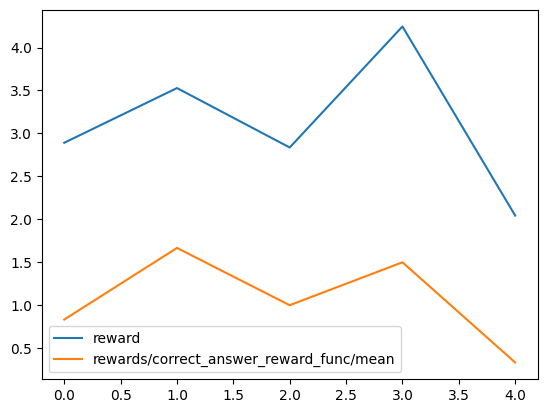

In [16]:
# Show the total (sum) of the rewards as well as the correct_answer_reward_func (means with in the batch)
# No changes needed in this cell

import pandas as pd
import matplotlib.pyplot as plt

# If you want to graph other columns, check these out
print(f"available columns: {trainer.state.log_history[0].keys()}")

log_df = pd.DataFrame(trainer.state.log_history)
log_df["reward"].plot()
log_df["rewards/correct_answer_reward_func/mean"].plot()

# Show the legend
plt.legend(["reward", "rewards/correct_answer_reward_func/mean"])
plt.show()

### Slower train (1+ hour)

If everything looks good, let's go for a longer training session!

In [17]:
# Now let's train for real! Let's do a longer training that will take an hour or more
# Note: If this run is successful, you can consider doing a longer train
# to see what happens, but that's beyond the scope of this project.
# Done: Fill out the areas where you find **********

# Full training
training_args = GRPOConfig(
    **COMMON_GRPO_TRAINING_PARAMS,
    # Configure the maximum number of steps to take about an hour for
    # a medium-sized experiment. (See how long the previous example took and
    # scale up appropriately using your best guess.)
    max_steps=100,  # ~60min
)
trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=REWARD_FUNCS,
    args=training_args,
    train_dataset=ds,
)
trainer_res = trainer.train()

Unsloth: We now expect `per_device_train_batch_size` * `gradient_accumulation_steps` * `world_size` to be a multiple of `num_generations`.
We will change the batch size of 4 to the `num_generations` of 6
Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.
Unsloth: `max_prompt_length` is not supported by the installed TRL's GRPOConfig and will be IGNORED - filter overlong prompts out of your dataset before training instead.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 401 | Num Epochs = 1 | Total steps = 100
O^O/ \_/ \    Batch size per device = 6 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (6 x 2 x 1) = 12
 "-____-"     Trainable parameters = 29,933,568 of 1,830,055,936 (1.64% trained)



--------------------
Question: How many of the letter "g" are there in the word "glisten"
Answer: 1
Response: <reasoning>
Counting the number of g's in the word glisten
1. g - 1 so far
2. i - 1 so far
3. s - 1 so far
4. t - 1 so far
5. e - 1 so far
6. n - 1 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / numbering_reward_func / mean,rewards / numbering_reward_func / std,rewards / spelling_reward_func / mean,rewards / spelling_reward_func / std,rewards / counting_reward_func / mean,rewards / counting_reward_func / std,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / correct_answer_reward_func / mean,rewards / correct_answer_reward_func / std
1,0.046039,3.398504,1.637916,76.833336,65.000000,93.000000,0.000000,76.833336,65.000000,93.000000,0.083845,0.857143,0.279145,0.562195,0.335534,0.145833,0.722431,1.000000,0.000000,0.833333,1.029857
2,-0.012040,4.828999,1.208737,77.666672,66.000000,90.000000,0.000000,77.666672,66.000000,90.000000,0.085862,1.000000,0.000000,0.899832,0.233983,0.262500,0.571730,1.000000,0.000000,1.666667,0.778499
3,-0.000385,2.668260,1.586930,83.166672,65.000000,111.000000,0.000000,83.166672,65.000000,111.000000,0.077526,0.968750,0.056533,0.480760,0.463001,-0.614583,0.258153,1.000000,0.000000,0.833333,1.029857
4,-0.007160,4.594907,1.419207,77.083336,70.000000,93.000000,0.000000,77.083336,70.000000,93.000000,0.112673,1.000000,0.000000,0.832407,0.303975,0.262500,0.308313,1.000000,0.000000,1.500000,0.904534
5,-0.016598,3.028971,1.444884,89.166672,79.000000,97.000000,0.000000,89.166672,79.000000,97.000000,0.103797,0.855159,0.285797,0.388098,0.324017,-0.047619,0.493516,1.000000,0.000000,0.833333,1.029857
6,0.000123,5.020147,0.697420,79.000000,70.000000,88.000000,0.000000,79.000000,70.000000,88.000000,0.122339,0.928571,0.074605,0.698718,0.317515,0.392857,0.487792,1.000000,0.000000,2.000000,0.000000
7,-0.038366,2.618687,1.292333,86.833336,79.000000,97.000000,0.000000,86.833336,79.000000,97.000000,0.162581,0.916667,0.087039,0.396465,0.301154,-0.527778,0.273708,1.000000,0.000000,0.833333,1.029857
8,-0.010286,3.770202,1.620882,86.666672,72.000000,97.000000,0.000000,86.666672,72.000000,97.000000,0.142861,0.763889,0.533988,0.506313,0.490517,-0.291667,0.267092,0.958333,0.144338,1.833333,0.577350
9,-0.028464,3.967088,1.570320,88.416672,79.000000,115.000000,0.000000,88.416672,79.000000,115.000000,0.126532,0.952778,0.085821,0.833754,0.303370,0.180556,0.542061,1.000000,0.000000,1.000000,1.044466
10,0.000250,3.063187,0.741492,79.000000,70.000000,88.000000,0.000000,79.000000,70.000000,88.000000,0.254057,0.928571,0.074605,0.634615,0.381632,0.000000,0.000000,1.000000,0.000000,0.500000,0.904534



--------------------
Question: How many of the letter "a" are there in the word "knack"
Answer: 1
Response: <reasoning>
Counting the number of a's in the word knack
1. k - 0 so far
2. n - 1 so far
3. a - 1 (at position 3) so far
4. k - 1 so far
5. c - 1 so far
6. k - 1 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    

--------------------
Question: How many of the letter "e" are there in the word "sapphire"
Answer: 1
Response: <reasoning>
Counting the number of e's in the word sapphire
1. s - 0 so far
2. a - 1 so far
3. p - 1 so far
4. a - 2 so far
5. p - 3 so far
6. a - 3 so far
7. y - 3 so far
8. e - 4 so far
</reasoning>
<answer>
4
</answer>
Extracted: 4
Correct: False!
    

--------------------
Question: How many of the letter "s" are there in the word "aisle"
Answer: 1
Response: <reasoning>
Counting the number of s's in the word aisle
1. a - 0 so far
2. i - 1 so far
3. s - 1 (at position 3) so far
4. l - 1 so far
5. e - 2 so far
</reasoning>
<answer>
1
<

Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-20/tokenizer_config.json.


... (4 outputs left out)


--------------------
Question: How many of the letter "n" are there in the word "enchant"
Answer: 2
Response: <reasoning>
Counting the number of [letter_to_count]'s in the word [word]
1. e - 0 so far
2. n - 1 so far
3. c - 1 so far
4. h - 1 so far
5. a - 1 so far
6. n - 1 (new count) + 1 (existing) = 2 so far
7. t - 2 so far
</reasoning>
<answer>
2
</answer>
Extracted: 2
Correct: True!
    

--------------------
Question: How many of the letter "u" are there in the word "cipher"
Answer: 0
Response: <reasoning>
Counting the number of [letter_to_count]'s in the word [word]
1. c - 0 so far
2. i - 0 so far
3. p - 0 so far
4. e - 0 so far
5. e - 0 so far
6. r - 0 so far
</reasoning>
<answer>
0
</answer>
Extracted: 0
Correct: True!
    

--------------------
Question: How many of the letter "h" are there in the word "lush"
Answer: 1
Response: <reasoning>
Counting the number of [letter_to_count]'s in the word [word]
1. l - 0 so far
2. u - 0 so far
3. s - 0 so far
4. h - 1 so far
</reasoning>

Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-80/tokenizer_config.json.



--------------------
Question: How many of the letter "i" are there in the word "mirage"
Answer: 1
Response: <reasoning>
Counting the number of [letter_to_count]'s in the word [word]
1. m - 0 so far
2. i - 1 so far
3. r - 1 so far
4. a - 1 so far
5. g - 1 so far
6. e - 1 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    

--------------------
Question: How many of the letter "t" are there in the word "glisten"
Answer: 1
Response: <reasoning>
Counting the number of [letter_to_count]'s in the word [word]
1. g - 0 so far
2. i - 0 so far
3. s - 0 so far
4. l - 0 so far
5. e - 0 so far
6. n - 0 so far
</reasoning>
<answer>
0
</answer>
Extracted: 0
Correct: False!
    

--------------------
Question: How many of the letter "r" are there in the word "lunar"
Answer: 1
Response: <reasoning>
Counting the number of [letter_to_count]'s in the word [word]
1. l - 0 so far
2. u - 0 so far
3. a - 0 so far
4. n - 0 so far
5. e - 0 so far
</reasoning>
<answer>
0
</answer>
Extract

Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-100/tokenizer_config.json.


available columns: dict_keys(['loss', 'grad_norm', 'learning_rate', 'num_tokens', 'completions/mean_length', 'completions/min_length', 'completions/max_length', 'completions/clipped_ratio', 'completions/mean_terminated_length', 'completions/min_terminated_length', 'completions/max_terminated_length', 'rewards/numbering_reward_func/mean', 'rewards/numbering_reward_func/std', 'rewards/spelling_reward_func/mean', 'rewards/spelling_reward_func/std', 'rewards/counting_reward_func/mean', 'rewards/counting_reward_func/std', 'rewards/format_reward_func/mean', 'rewards/format_reward_func/std', 'rewards/correct_answer_reward_func/mean', 'rewards/correct_answer_reward_func/std', 'reward', 'reward_std', 'frac_reward_zero_std', 'completion_length', 'kl', 'clip_ratio/low_mean', 'clip_ratio/low_min', 'clip_ratio/high_mean', 'clip_ratio/high_max', 'clip_ratio/region_mean', 'step_time', 'epoch', 'step'])


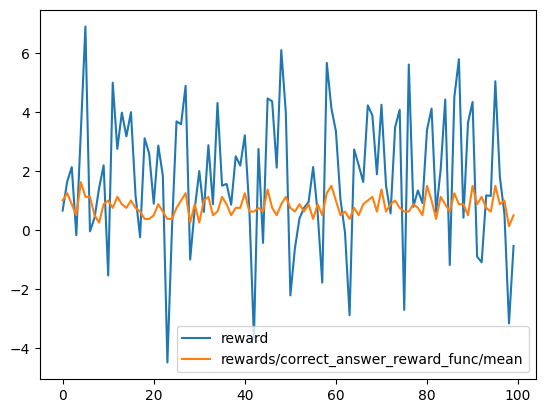

In [19]:
# Show the total (sum) of the rewards as well as the correct_answer_reward_func (means with in the batch)
# Do you see the rewards increasing? Does the model get the correct answer
# more frequently toward the end?
# No changes needed in this cell

import pandas as pd
import matplotlib.pyplot as plt

# If you want to graph other columns, check these out
print(f"available columns: {trainer.state.log_history[0].keys()}")

log_df = pd.DataFrame(trainer.state.log_history)
log_df["reward"].plot()
log_df["rewards/correct_answer_reward_func/mean"].plot()

# Show the legend
plt.legend(["reward", "rewards/correct_answer_reward_func/mean"])
plt.show()

### If your session stopped during the Slower train

Checkpoints are saved in `outputs/` every 20 steps. They survive a kernel **Restart** and **End Lab**, but not **Reset**.

1. If the lab ended, start it again and select **Python (venv2)**.
2. Run every cell from the top down to and including the `COMMON_GRPO_TRAINING_PARAMS` cell. Skip the Quick train.
3. In the Slower train cell above, keep the same `max_steps` and change the last line to `trainer_res = trainer.train(resume_from_checkpoint=True)`, then run it.
4. Re-run the plotting cell — it shows the whole run.

Download your notebook (right-click it in the file explorer → **Download**) before you ever use the lab's **Reset** button: Reset erases your work and it can't be recovered.

## View the results
Now let's try the model we just trained!

In [20]:
# Save the LoRA adapters
# No changes needed in this cell

# Save the LoRA model
model.save_lora("grpo_saved_lora")

In [21]:
# Create a function to run both the original model and the updated model
# No changes needed in this cell


def compare_old_and_new_model(messages):
    from vllm import SamplingParams

    text = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    sampling_params = SamplingParams(
        temperature=0.8,
        top_p=0.95,
        max_tokens=1024,
    )
    old = (
        model.fast_generate(
            text,
            sampling_params=sampling_params,
        )[0]
        .outputs[0]
        .text
    )

    new = (
        model.fast_generate(
            text,
            sampling_params=sampling_params,
            lora_request=model.load_lora("grpo_saved_lora"),
        )[0]
        .outputs[0]
        .text
    )

    print("===OLD===\n")
    print(old)

    print("\n\n===NEW===\n")
    print(new)


### Compare the old and new models on the letter-counting task

In [26]:
# Let's try spelling the first word from the dataset
# Fill out the areas where you find **********

# Load the first item from the dataset (index 0) and compare the old and new models
prompt_messages = ds[0]['prompt']
compare_old_and_new_model(prompt_messages)

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

===OLD===

<reasoning>
Counting the number of a's in the word idea
1. i - 0 so far
2. d - 1 so far
3. e - 2 so far
4. a - 3 so far
</reasoning>
<answer>
3
</answer>


===NEW===

<reasoning>
Counting the number of "a"s in the word "idea"
1. i - 0 so far
2. d - 1 so far
3. e - 2 so far
4. a - 3 so far
</reasoning>
<answer>
3
</answer>


Our model is better at spelling and counting letters in words! Depending on your reward functions, the size of your model, and the amount of steps trained, results may vary.

For about an hour of training time, your model may not be perfect (or maybe it is), but it's definitely moving in the right direction!

### Make sure the model did not forget basic facts

In [27]:
# Let's see if the model still remembers some of the facts from its original training
# Ask both the old and new models a question the model is likely to know,
# e.g. a well-known capital city

fact_prompt = [
    {"role": "user", "content": "What is the capital of France?"}
]

compare_old_and_new_model(fact_prompt)

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Rendering prompts:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

===OLD===

The capital of France is Paris.


===NEW===

The capital of France is Paris.


Great job! Congrats on completing the project! 🎉🤗